# 🔴 PRÁCTICA: ANÁLISIS Y VISUALIZACIÓN DE CALIFICACIONES CON PANDAS Y MATPLOTLIB
### Ingeniería en Sistemas Computacionales (ISC) — Tópicos Avanzados de Programación
> **Estética Visual:** Cyberpunk / Modern Dark  
> **Paleta Cromática:** Fondo Negro Profundo (`#070709` / `#0b0b0b`), Acentos Neón Rojo (`#ff1e42` / `#ff0055`) y Textos Blanco Puro (`#ffffff`).

---

## 🎯 Objetivos de la Práctica
1. **Carga y Exploración Inicial:** Lectura de datos relacionales en formato ordenado (*tidy data*) y verificación dimensional (288 filas × 7 columnas).
2. **Filtros Vectorizados:** Consulta de subconjuntos de datos mediante máscaras booleanas sin utilizar bucles iterativos `for` ni `while`.
3. **Columna Calculada:** Creación de la métrica de aprobación académica con `np.where` vectorizado.
4. **Resúmenes Estadísticos:** Agrupaciones multidimensionales con `groupby()`, cálculo de medias y exportación a archivo CSV (`promedios_alumnos.csv`).
5. **Visualización de Datos:** Construcción de tres gráficos de alta resolución (300 DPI) bajo la estética Cyberpunk Dark & Red Neon.
6. **Interpretación y Análisis Crítico:** Deducción de patrones de rendimiento académico e identificación de estudiantes en riesgo.

---
## ⚙️ Configuración del Entorno y Estilo Cyberpunk
Inicializamos las librerías científicas (`pandas`, `numpy`, `matplotlib`) y configuramos la paleta de colores de alto contraste neón para todos los gráficos del notebook.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reconfigurar codificación estándar para salidas limpias
if sys.stdout.encoding != "utf-8":
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

# Configuración del estilo Cyberpunk Dark / Neon Red
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": "#0b0b0b",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#ff1e42",
    "axes.linewidth": 1.4,
    "axes.labelcolor": "#ffffff",
    "xtick.color": "#ffffff",
    "ytick.color": "#ffffff",
    "text.color": "#ffffff",
    "grid.color": "#ff1e42",
    "grid.alpha": 0.18,
    "grid.linestyle": "--",
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Helvetica", "Arial"],
    "figure.titlesize": 14,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

print("✅ Entorno configurado con éxito. Tema Cyberpunk Red Neon activo.")

✅ Entorno configurado con éxito. Tema Cyberpunk Red Neon activo.


---
## 📋 Ejercicio 1: Carga y Exploración Inicial del Dataset
En este ejercicio se realiza la lectura del archivo `calificaciones_isc.csv` mediante Pandas y se verifican sus propiedades estructurales:
- **`head()`**: Vista de las primeras filas.
- **`shape`**: Dimensiones del DataFrame.
- **`dtypes`**: Tipos de datos por columna.
- **`describe()`**: Resumen estadístico de las variables cuantitativas (`calificacion`, `asistencias`).

### 💡 ¿Por qué el dataset contiene exactamente 288 filas y no 24?
El dataset está diseñado bajo el estándar de **formato largo (*tidy data* / long format)**, donde cada fila corresponde a una observación individual: la calificación obtenida por **un alumno** en **una unidad evaluativa** de **una materia** en particular.
$$\text{Total Filas} = 24 \text{ alumnos (12 Grupo A + 12 Grupo B)} \times 4 \text{ materias} \times 3 \text{ unidades} = 288 \text{ registros}$$
Si el archivo tuviese únicamente 24 filas (una por alumno), estaría en formato ancho (*wide format*) con 12 columnas distintas de calificaciones, lo cual impediría aplicar agregaciones directas, filtros temporales por unidad o comparativas entre asignaturas.

In [2]:
# Cargar el dataset en un DataFrame de Pandas
ruta_csv = Path("calificaciones_isc.csv")
df = pd.read_csv(ruta_csv)

print("=" * 70)
print("1. PRIMERAS FILAS DEL DATASET (df.head):")
print("=" * 70)
print(df.head(10).to_string(index=False))

print("\n" + "=" * 70)
print(f"2. DIMENSIONES DEL DATAFRAME (df.shape): {df.shape[0]} filas × {df.shape[1]} columnas")
print("=" * 70)

print("\n" + "=" * 70)
print("3. TIPOS DE DATOS DE LAS COLUMNAS (df.dtypes):")
print("=" * 70)
print(df.dtypes)

print("\n" + "=" * 70)
print("4. ESTADÍSTICAS DESCRIPTIVAS (df.describe):")
print("=" * 70)
print(df[["calificacion", "asistencias"]].describe().round(2))

1. PRIMERAS FILAS DEL DATASET (df.head):
matricula            nombre grupo               materia  unidad  calificacion  asistencias
ISC240101 Alejandro Navarro     A          Programacion       1            96           27
ISC240101 Alejandro Navarro     A          Programacion       2            88           29
ISC240101 Alejandro Navarro     A          Programacion       3            85           28
ISC240101 Alejandro Navarro     A        Bases de datos       1            86           27
ISC240101 Alejandro Navarro     A        Bases de datos       2            96           30
ISC240101 Alejandro Navarro     A        Bases de datos       3            81           30
ISC240101 Alejandro Navarro     A                 Redes       1            88           27
ISC240101 Alejandro Navarro     A                 Redes       2            84           27
ISC240101 Alejandro Navarro     A                 Redes       3            81           28
ISC240101 Alejandro Navarro     A Matematicas dis

---
## 🔍 Ejercicio 2: Filtros Vectorizados (Sin Bucles)
En Pandas, las consultas de datos deben realizarse mediante **máscaras booleanas vectorizadas** (`df[condicion]`), aprovechando optimizaciones en código binario C/NumPy y evitando bucles `for` o `while` tradicionales.

Se aplican los siguientes filtros requeridos:
1. **Filtro A:** Todas las filas correspondientes al **Grupo A**.
2. **Filtro B:** Registros con **calificación menor a 70** (unidades no aprobadas).
3. **Filtro C:** Registros de la materia **"Bases de datos"** del **Grupo B** con calificación **$\ge 80$**.

In [3]:
# Filtro A: Todas las filas correspondientes al Grupo A
filtro_grupo_a = df[df["grupo"] == "A"]
print(f"A) Total de registros del Grupo A: {len(filtro_grupo_a)} filas (12 alumnos × 12 unidades)")
print(filtro_grupo_a.head(3).to_string(index=False))

# Filtro B: Registros con calificación menor a 70
filtro_reprobados = df[df["calificacion"] < 70]
print(f"\nB) Total de registros con calificación < 70: {len(filtro_reprobados)} unidades")
print(filtro_reprobados.head(4).to_string(index=False))

# Filtro C: Registros de 'Bases de datos' en Grupo B con calificación >= 80
filtro_bd_b_80 = df[
    (df["materia"] == "Bases de datos") &
    (df["grupo"] == "B") &
    (df["calificacion"] >= 80)
]
print(f"\nC) Registros de 'Bases de datos' en Grupo B con calificación >= 80: {len(filtro_bd_b_80)} registros")
print(filtro_bd_b_80[["matricula", "nombre", "unidad", "calificacion"]].to_string(index=False))

A) Total de registros del Grupo A: 144 filas (12 alumnos × 12 unidades)
matricula            nombre grupo      materia  unidad  calificacion  asistencias
ISC240101 Alejandro Navarro     A Programacion       1            96           27
ISC240101 Alejandro Navarro     A Programacion       2            88           29
ISC240101 Alejandro Navarro     A Programacion       3            85           28

B) Total de registros con calificación < 70: 59 unidades
matricula          nombre grupo               materia  unidad  calificacion  asistencias
ISC240103 Carlos Espinoza     A                 Redes       3            64           26
ISC240103 Carlos Espinoza     A Matematicas discretas       2            66           26
ISC240103 Carlos Espinoza     A Matematicas discretas       3            60           28
ISC240105   Diego Ramirez     A          Programacion       1            68           24

C) Registros de 'Bases de datos' en Grupo B con calificación >= 80: 26 registros
matricula      

---
## ⚡ Ejercicio 3: Columna Calculada `situacion` con `np.where`
Para categorizar el estatus académico de cada evaluación unitaria sin recurrir a iteraciones lentas, utilizamos la función vectorizada `np.where()`:
$$\text{situacion} = \begin{cases} \text{'Aprobado'}, & \text{si } \text{calificación} \ge 70 \\ \text{'Reprobado'}, & \text{si } \text{calificación} < 70 \end{cases}$$

In [4]:
# Creación vectorizada de la columna 'situacion'
df["situacion"] = np.where(df["calificacion"] >= 70, "Aprobado", "Reprobado")

print("Muestra con la nueva columna 'situacion':")
print(df[["matricula", "nombre", "materia", "unidad", "calificacion", "situacion"]].head(8).to_string(index=False))

# Conteo y distribución porcentual
conteo_situacion = df["situacion"].value_counts()
print("\nDistribución global de la situación académica:")
for estado, total in conteo_situacion.items():
    pct = (total / len(df)) * 100
    print(f"  • {estado}: {total} registros ({pct:.2f}%)")

Muestra con la nueva columna 'situacion':
matricula            nombre        materia  unidad  calificacion situacion
ISC240101 Alejandro Navarro   Programacion       1            96  Aprobado
ISC240101 Alejandro Navarro   Programacion       2            88  Aprobado
ISC240101 Alejandro Navarro   Programacion       3            85  Aprobado
ISC240101 Alejandro Navarro Bases de datos       1            86  Aprobado
ISC240101 Alejandro Navarro Bases de datos       2            96  Aprobado
ISC240101 Alejandro Navarro Bases de datos       3            81  Aprobado
ISC240101 Alejandro Navarro          Redes       1            88  Aprobado
ISC240101 Alejandro Navarro          Redes       2            84  Aprobado

Distribución global de la situación académica:
  • Aprobado: 229 registros (79.51%)
  • Reprobado: 59 registros (20.49%)


---
## 📊 Ejercicio 4: Agrupaciones, Resúmenes Estadísticos y Exportación a CSV
Aplicamos el paradigma *Split-Apply-Combine* mediante `df.groupby()` para derivar métricas consolidadas:
1. **Promedio por materia.**
2. **Promedio por grupo y materia** (tabla cruzada con `.unstack()`).
3. **Promedio general por alumno** ordenado descendentemente.
4. **Promedio por unidad evaluativa (1, 2 y 3).**
5. **Conteo global de unidades Aprobadas vs Reprobadas.**
6. **Exportación a CSV:** Generación de `promedios_alumnos.csv` asegurando preservar los identificadores con `.reset_index()` e `index=False`.

In [5]:
# 4.1 Promedio de calificación por materia
prom_materia = df.groupby("materia")["calificacion"].mean().round(2)
print("--- 4.1 PROMEDIO POR MATERIA ---")
print(prom_materia.to_string())

# 4.2 Promedio por grupo y materia
prom_grupo_materia = df.groupby(["grupo", "materia"])["calificacion"].mean().round(2).unstack()
print("\n--- 4.2 PROMEDIO POR GRUPO Y MATERIA ---")
print(prom_grupo_materia.to_string())

# 4.3 Promedio general por alumno ordenado de mayor a menor
prom_alumnos = (
    df.groupby(["matricula", "nombre", "grupo"])
    .agg(
        promedio_calificacion=("calificacion", "mean"),
        promedio_asistencias=("asistencias", "mean"),
        unidades_aprobadas=("situacion", lambda s: (s == "Aprobado").sum()),
        unidades_reprobadas=("situacion", lambda s: (s == "Reprobado").sum()),
    )
    .round(2)
    .sort_values(by="promedio_calificacion", ascending=False)
    .reset_index()
)

print("\n--- 4.3 TOP 5 ALUMNOS CON MAYOR PROMEDIO GENERAL ---")
print(prom_alumnos.head(5).to_string(index=False))

print("\n--- 4.3 ÚLTIMOS 5 ALUMNOS (MENOR PROMEDIO GENERAL) ---")
print(prom_alumnos.tail(5).to_string(index=False))

# 4.4 Promedio por unidad evaluativa
prom_unidad = df.groupby("unidad")["calificacion"].mean().round(2)
print("\n--- 4.4 PROMEDIO POR UNIDAD EVALUATIVA ---")
print(prom_unidad.to_string())

# 4.5 Conteo global de Aprobados vs Reprobados
print("\n--- 4.5 CONTEO GLOBAL DE UNIDADES ---")
print(df["situacion"].value_counts().to_string())

# 4.6 Exportación de promedios_alumnos.csv
ruta_export_csv = Path("promedios_alumnos.csv")
prom_alumnos.to_csv(ruta_export_csv, index=False, encoding="utf-8")
print(f"\n✅ Archivo exportado exitosamente: {ruta_export_csv.resolve()}")
print(f"   Columnas exportadas: {list(prom_alumnos.columns)}")

--- 4.1 PROMEDIO POR MATERIA ---
materia
Bases de datos           82.21
Matematicas discretas    74.90
Programacion             84.76
Redes                    79.35

--- 4.2 PROMEDIO POR GRUPO Y MATERIA ---
materia  Bases de datos  Matematicas discretas  Programacion  Redes
grupo                                                              
A                 82.39                  74.75         84.61  78.61
B                 82.03                  75.06         84.92  80.08

--- 4.3 TOP 5 ALUMNOS CON MAYOR PROMEDIO GENERAL ---
matricula          nombre grupo  promedio_calificacion  promedio_asistencias  unidades_aprobadas  unidades_reprobadas
ISC240106  Mariana Torres     A                  94.83                 28.92                  12                    0
ISC240118 Luciana Delgado     B                  93.33                 28.50                  12                    0
ISC240102   Sofia Morales     A                  92.17                 28.42                  12                 

---
## 🎨 Ejercicio 5: Visualización de Datos con Estética Cyberpunk Dark & Neon Red
Se crean las 3 visualizaciones solicitadas garantizando:
- Fondo profundo (`#0b0b0b`), acentos en rojo neón (`#ff1e42`) y textos en blanco puro (`#ffffff`).
- Guardado en disco con `plt.savefig()` a **300 DPI** antes de mostrar y cerrar cada figura.
- Los archivos generados son:
  1. `promedio_materias.png` (Gráfico de barras)
  2. `histograma.png` (Histograma de frecuencias)
  3. `tendencia_unidades.png` (Gráfico de líneas con marcadores)

### 5.1 Gráfico de Barras: Promedio por Materia (`promedio_materias.png`)
Muestra la media de calificación de cada asignatura en una escala fija de 0 a 100, incluyendo la línea de mínimo aprobatorio (70 pts).

✅ Gráfica guardada: promedio_materias.png (300 DPI)


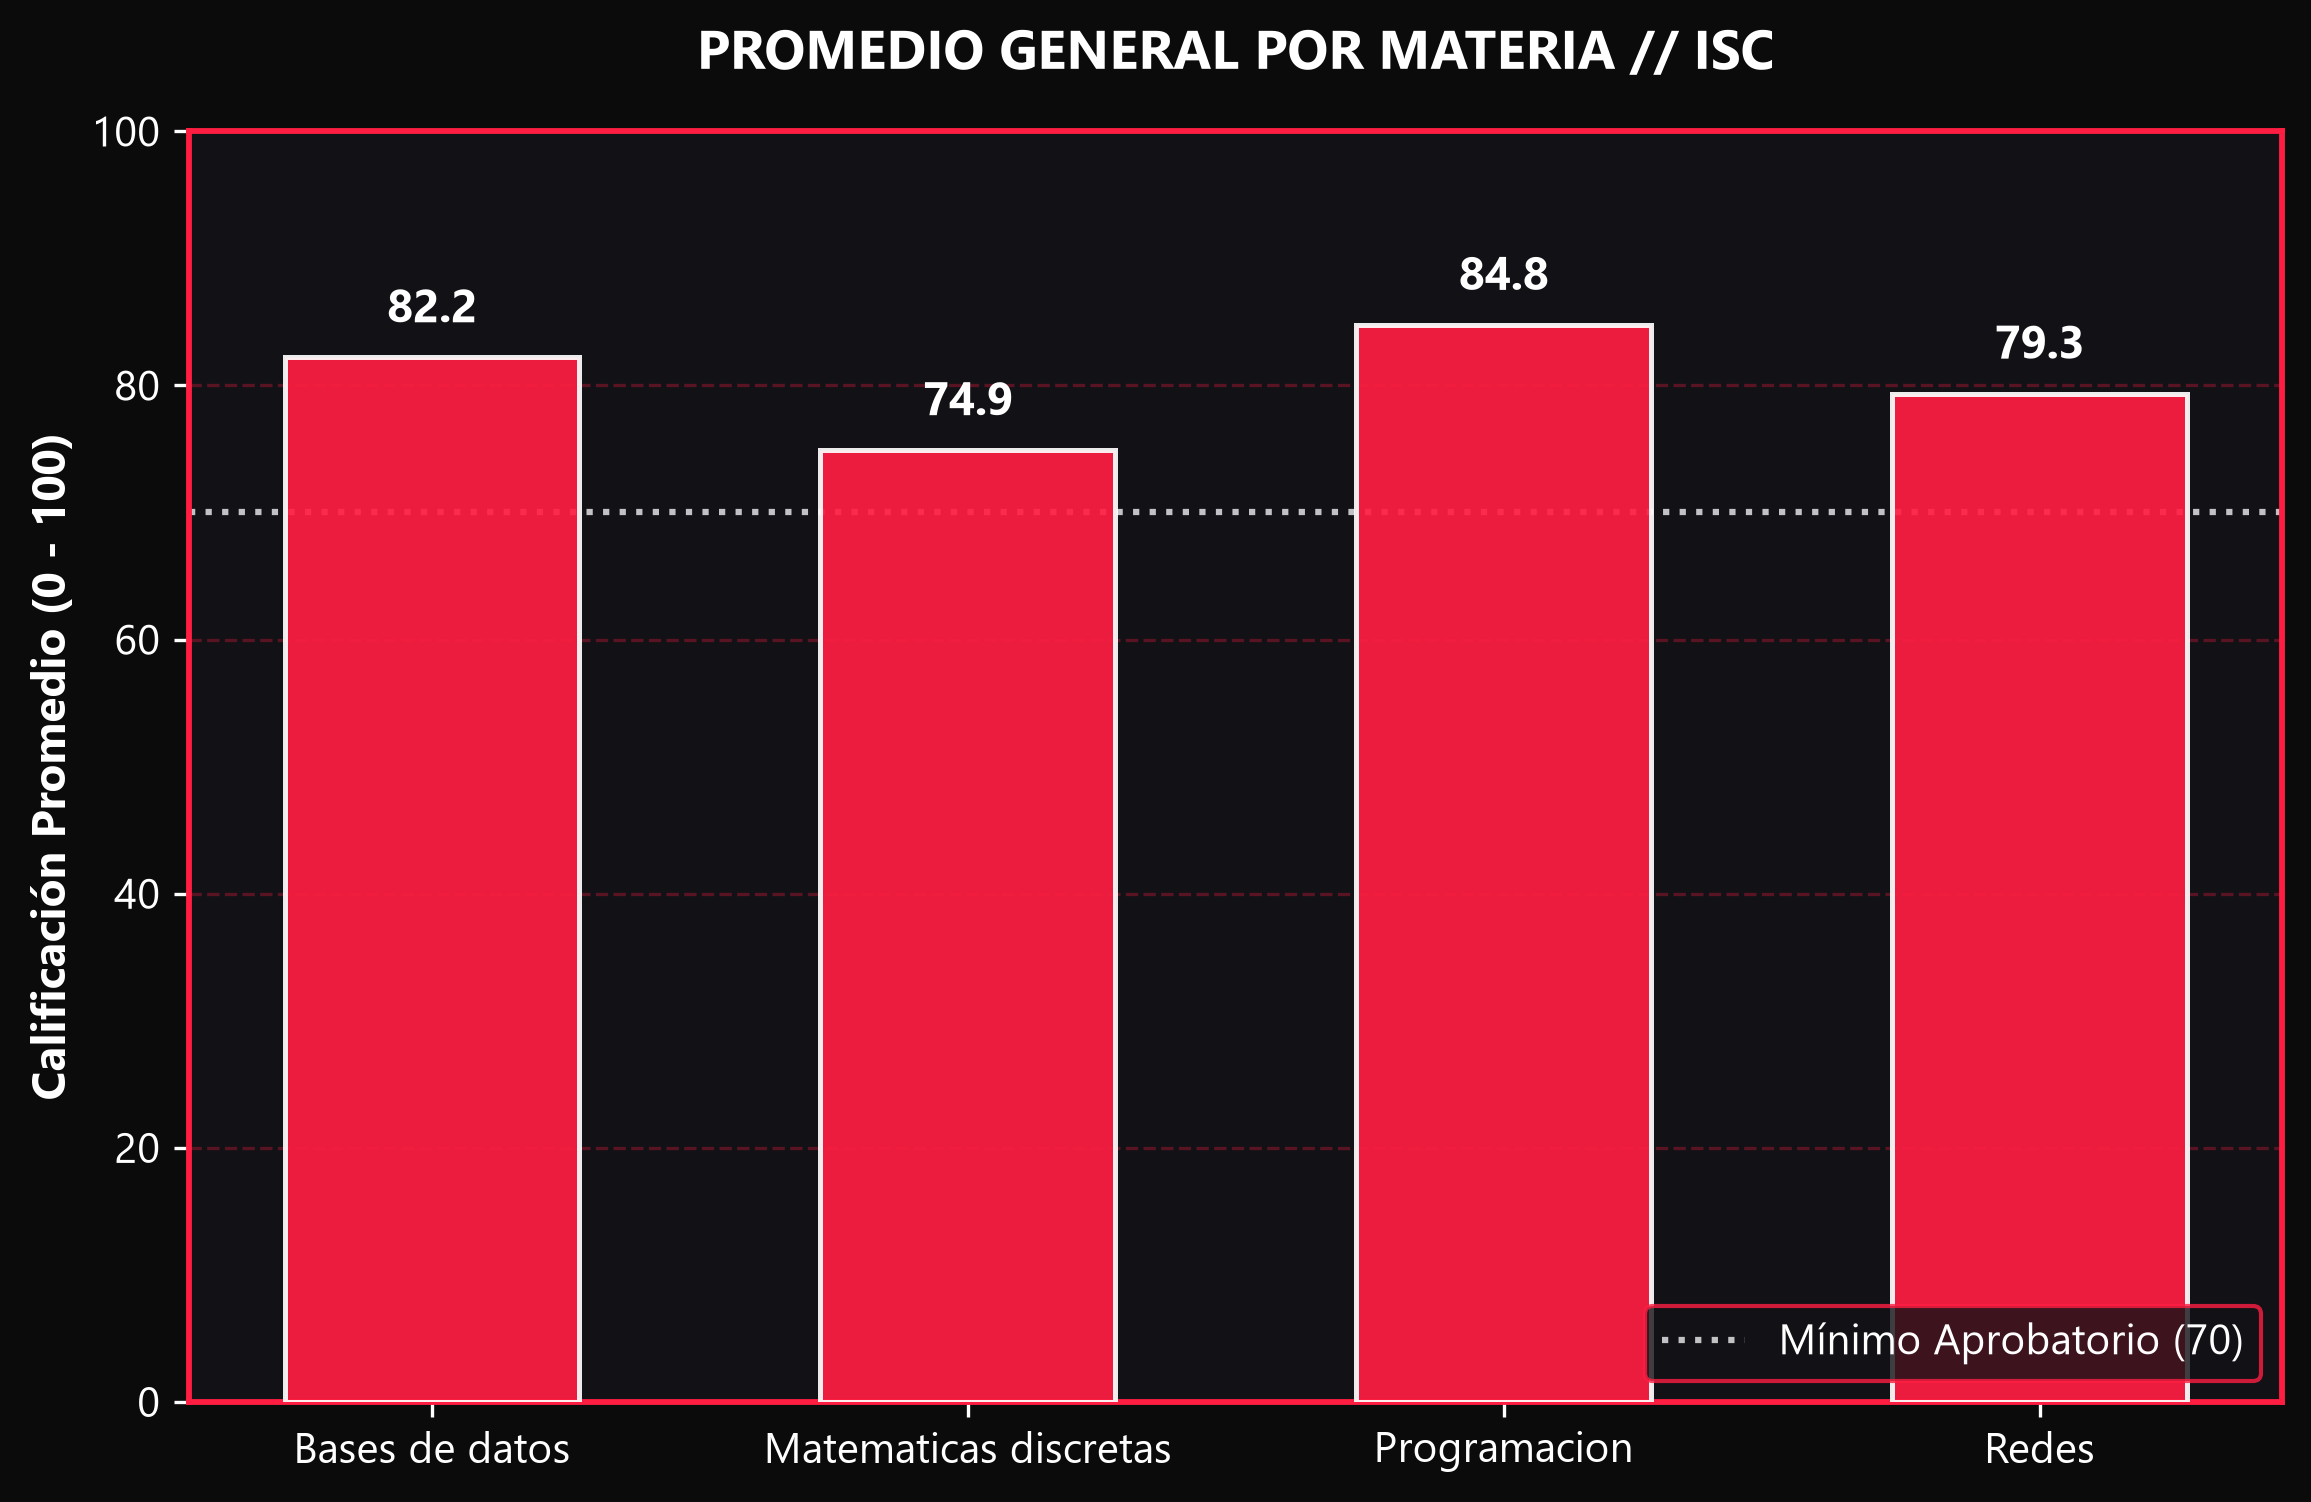

In [6]:
fig1, ax1 = plt.subplots(figsize=(9, 5.5), dpi=300)
materias_nombres = prom_materia.index.tolist()
materias_valores = prom_materia.values.tolist()

barras = ax1.bar(
    materias_nombres,
    materias_valores,
    color="#ff1e42",
    edgecolor="#ffffff",
    linewidth=1.2,
    width=0.55,
    alpha=0.92,
    zorder=3
)

ax1.set_ylim(0, 100)
ax1.set_ylabel("Calificación Promedio (0 - 100)", color="#ffffff", fontweight="bold")
ax1.set_title("PROMEDIO GENERAL POR MATERIA // ISC", color="#ffffff", fontweight="bold", pad=15)
ax1.grid(axis="y", linestyle="--", alpha=0.3, color="#ff1e42", zorder=0)

# Etiquetas de valor sobre cada barra
for barra in barras:
    altura = barra.get_height()
    ax1.text(
        barra.get_x() + barra.get_width() / 2.0,
        altura + 2.0,
        f"{altura:.1f}",
        ha="center",
        va="bottom",
        color="#ffffff",
        fontweight="bold",
        fontsize=11
    )

# Línea de referencia de aprobación mínima (70)
ax1.axhline(70, color="#ffffff", linestyle=":", linewidth=1.5, alpha=0.75, label="Mínimo Aprobatorio (70)")
ax1.legend(loc="lower right", facecolor="#111116", edgecolor="#ff1e42", labelcolor="#ffffff")

# Guardar figura a 300 DPI
plt.savefig("promedio_materias.png", dpi=300, bbox_inches="tight", facecolor=fig1.get_facecolor())
Path("static/plots").mkdir(parents=True, exist_ok=True)
plt.savefig("static/plots/promedio_materias.png", dpi=300, bbox_inches="tight", facecolor=fig1.get_facecolor())
print("✅ Gráfica guardada: promedio_materias.png (300 DPI)")
plt.show()

### 5.2 Histograma: Distribución de Calificaciones (`histograma.png`)
Distribución de frecuencia de las 288 evaluaciones con la línea vertical discontinua de aprobación en 70 puntos.

✅ Gráfica guardada: histograma.png (300 DPI)


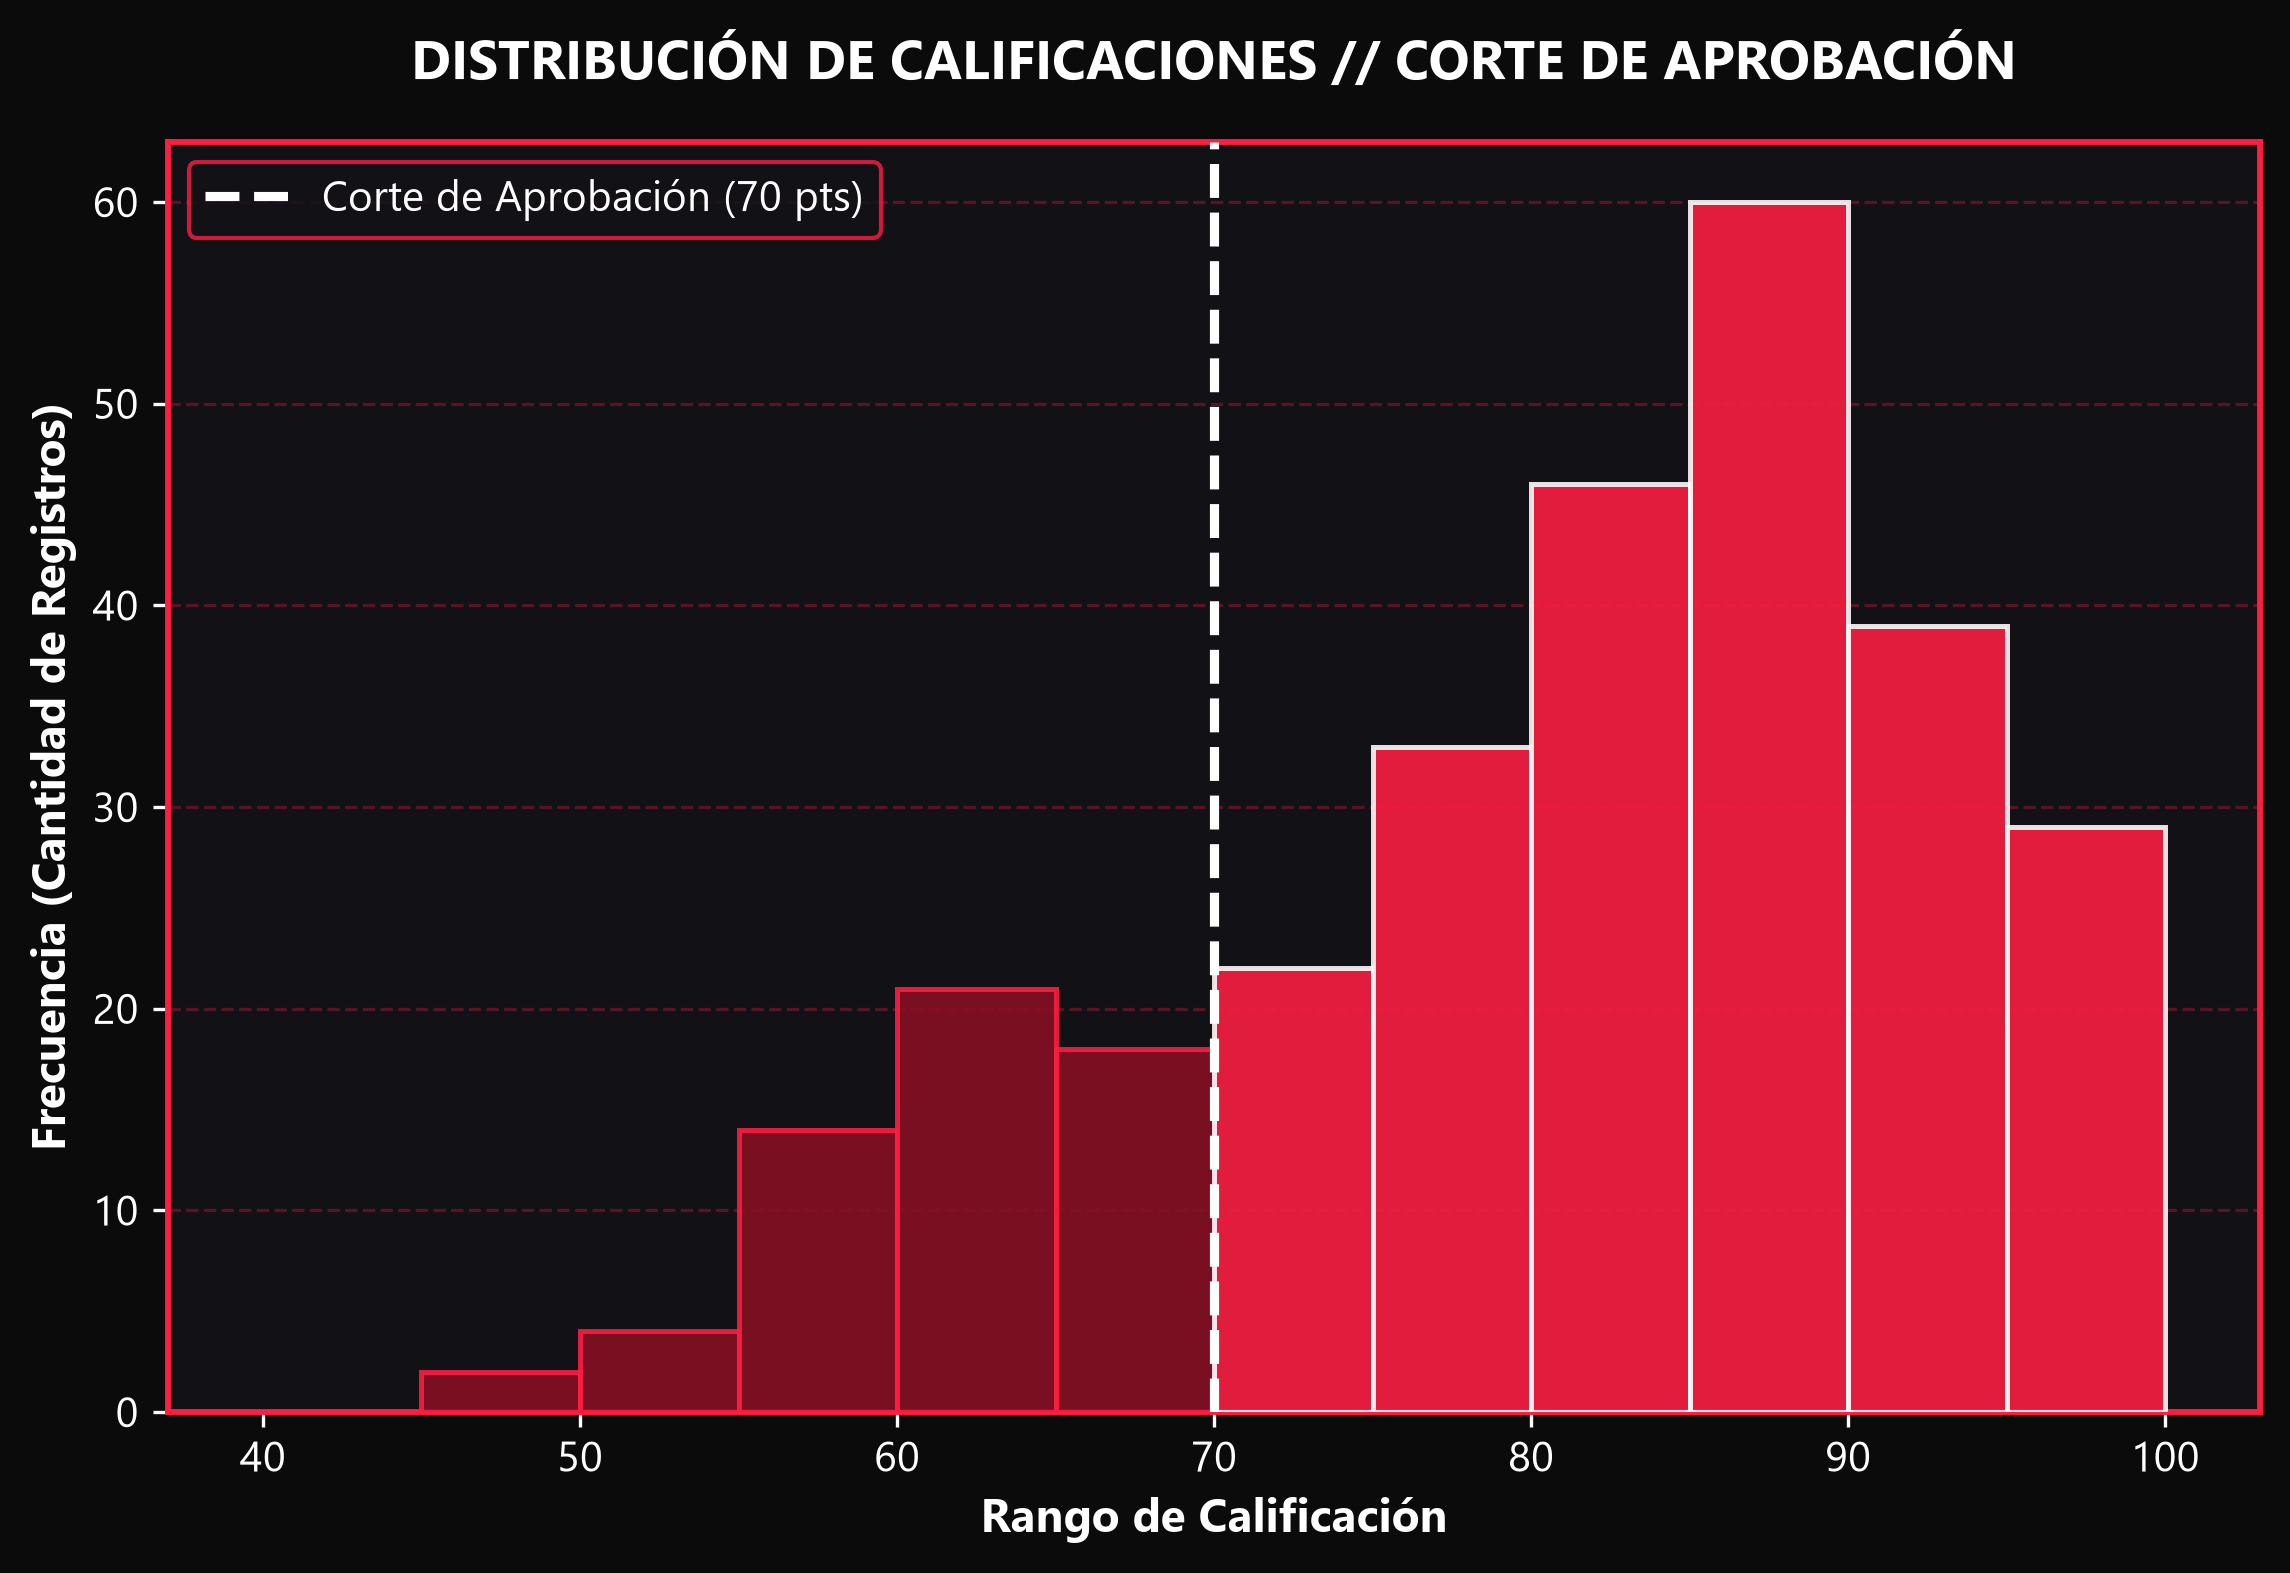

In [7]:
fig2, ax2 = plt.subplots(figsize=(9, 5.5), dpi=300)

n, bins, patches = ax2.hist(
    df["calificacion"],
    bins=12,
    range=(40, 100),
    color="#ff1e42",
    edgecolor="#ffffff",
    linewidth=1.2,
    alpha=0.88,
    zorder=3
)

# Coloreado semántico: carmesí oscuro para reprobados, rojo neón brillante para aprobados
for patch, bin_izq in zip(patches, bins[:-1]):
    if bin_izq < 70:
        patch.set_facecolor("#8a0f24")
        patch.set_edgecolor("#ff1e42")
    else:
        patch.set_facecolor("#ff1e42")
        patch.set_edgecolor("#ffffff")

# Línea de corte de aprobación en 70
ax2.axvline(
    70,
    color="#ffffff",
    linestyle="--",
    linewidth=2.2,
    zorder=4,
    label="Corte de Aprobación (70 pts)"
)

ax2.set_xlabel("Rango de Calificación", color="#ffffff", fontweight="bold")
ax2.set_ylabel("Frecuencia (Cantidad de Registros)", color="#ffffff", fontweight="bold")
ax2.set_title("DISTRIBUCIÓN DE CALIFICACIONES // CORTE DE APROBACIÓN", color="#ffffff", fontweight="bold", pad=15)
ax2.grid(axis="y", linestyle="--", alpha=0.3, color="#ff1e42", zorder=0)
ax2.legend(loc="upper left", facecolor="#111116", edgecolor="#ff1e42", labelcolor="#ffffff")

# Guardar figura a 300 DPI
plt.savefig("histograma.png", dpi=300, bbox_inches="tight", facecolor=fig2.get_facecolor())
plt.savefig("static/plots/histograma.png", dpi=300, bbox_inches="tight", facecolor=fig2.get_facecolor())
print("✅ Gráfica guardada: histograma.png (300 DPI)")
plt.show()

### 5.3 Gráfico de Líneas: Tendencia por Unidad y Materia (`tendencia_unidades.png`)
Evolución de las medias por asignatura a través de las Unidades 1, 2 y 3.

✅ Gráfica guardada: tendencia_unidades.png (300 DPI)


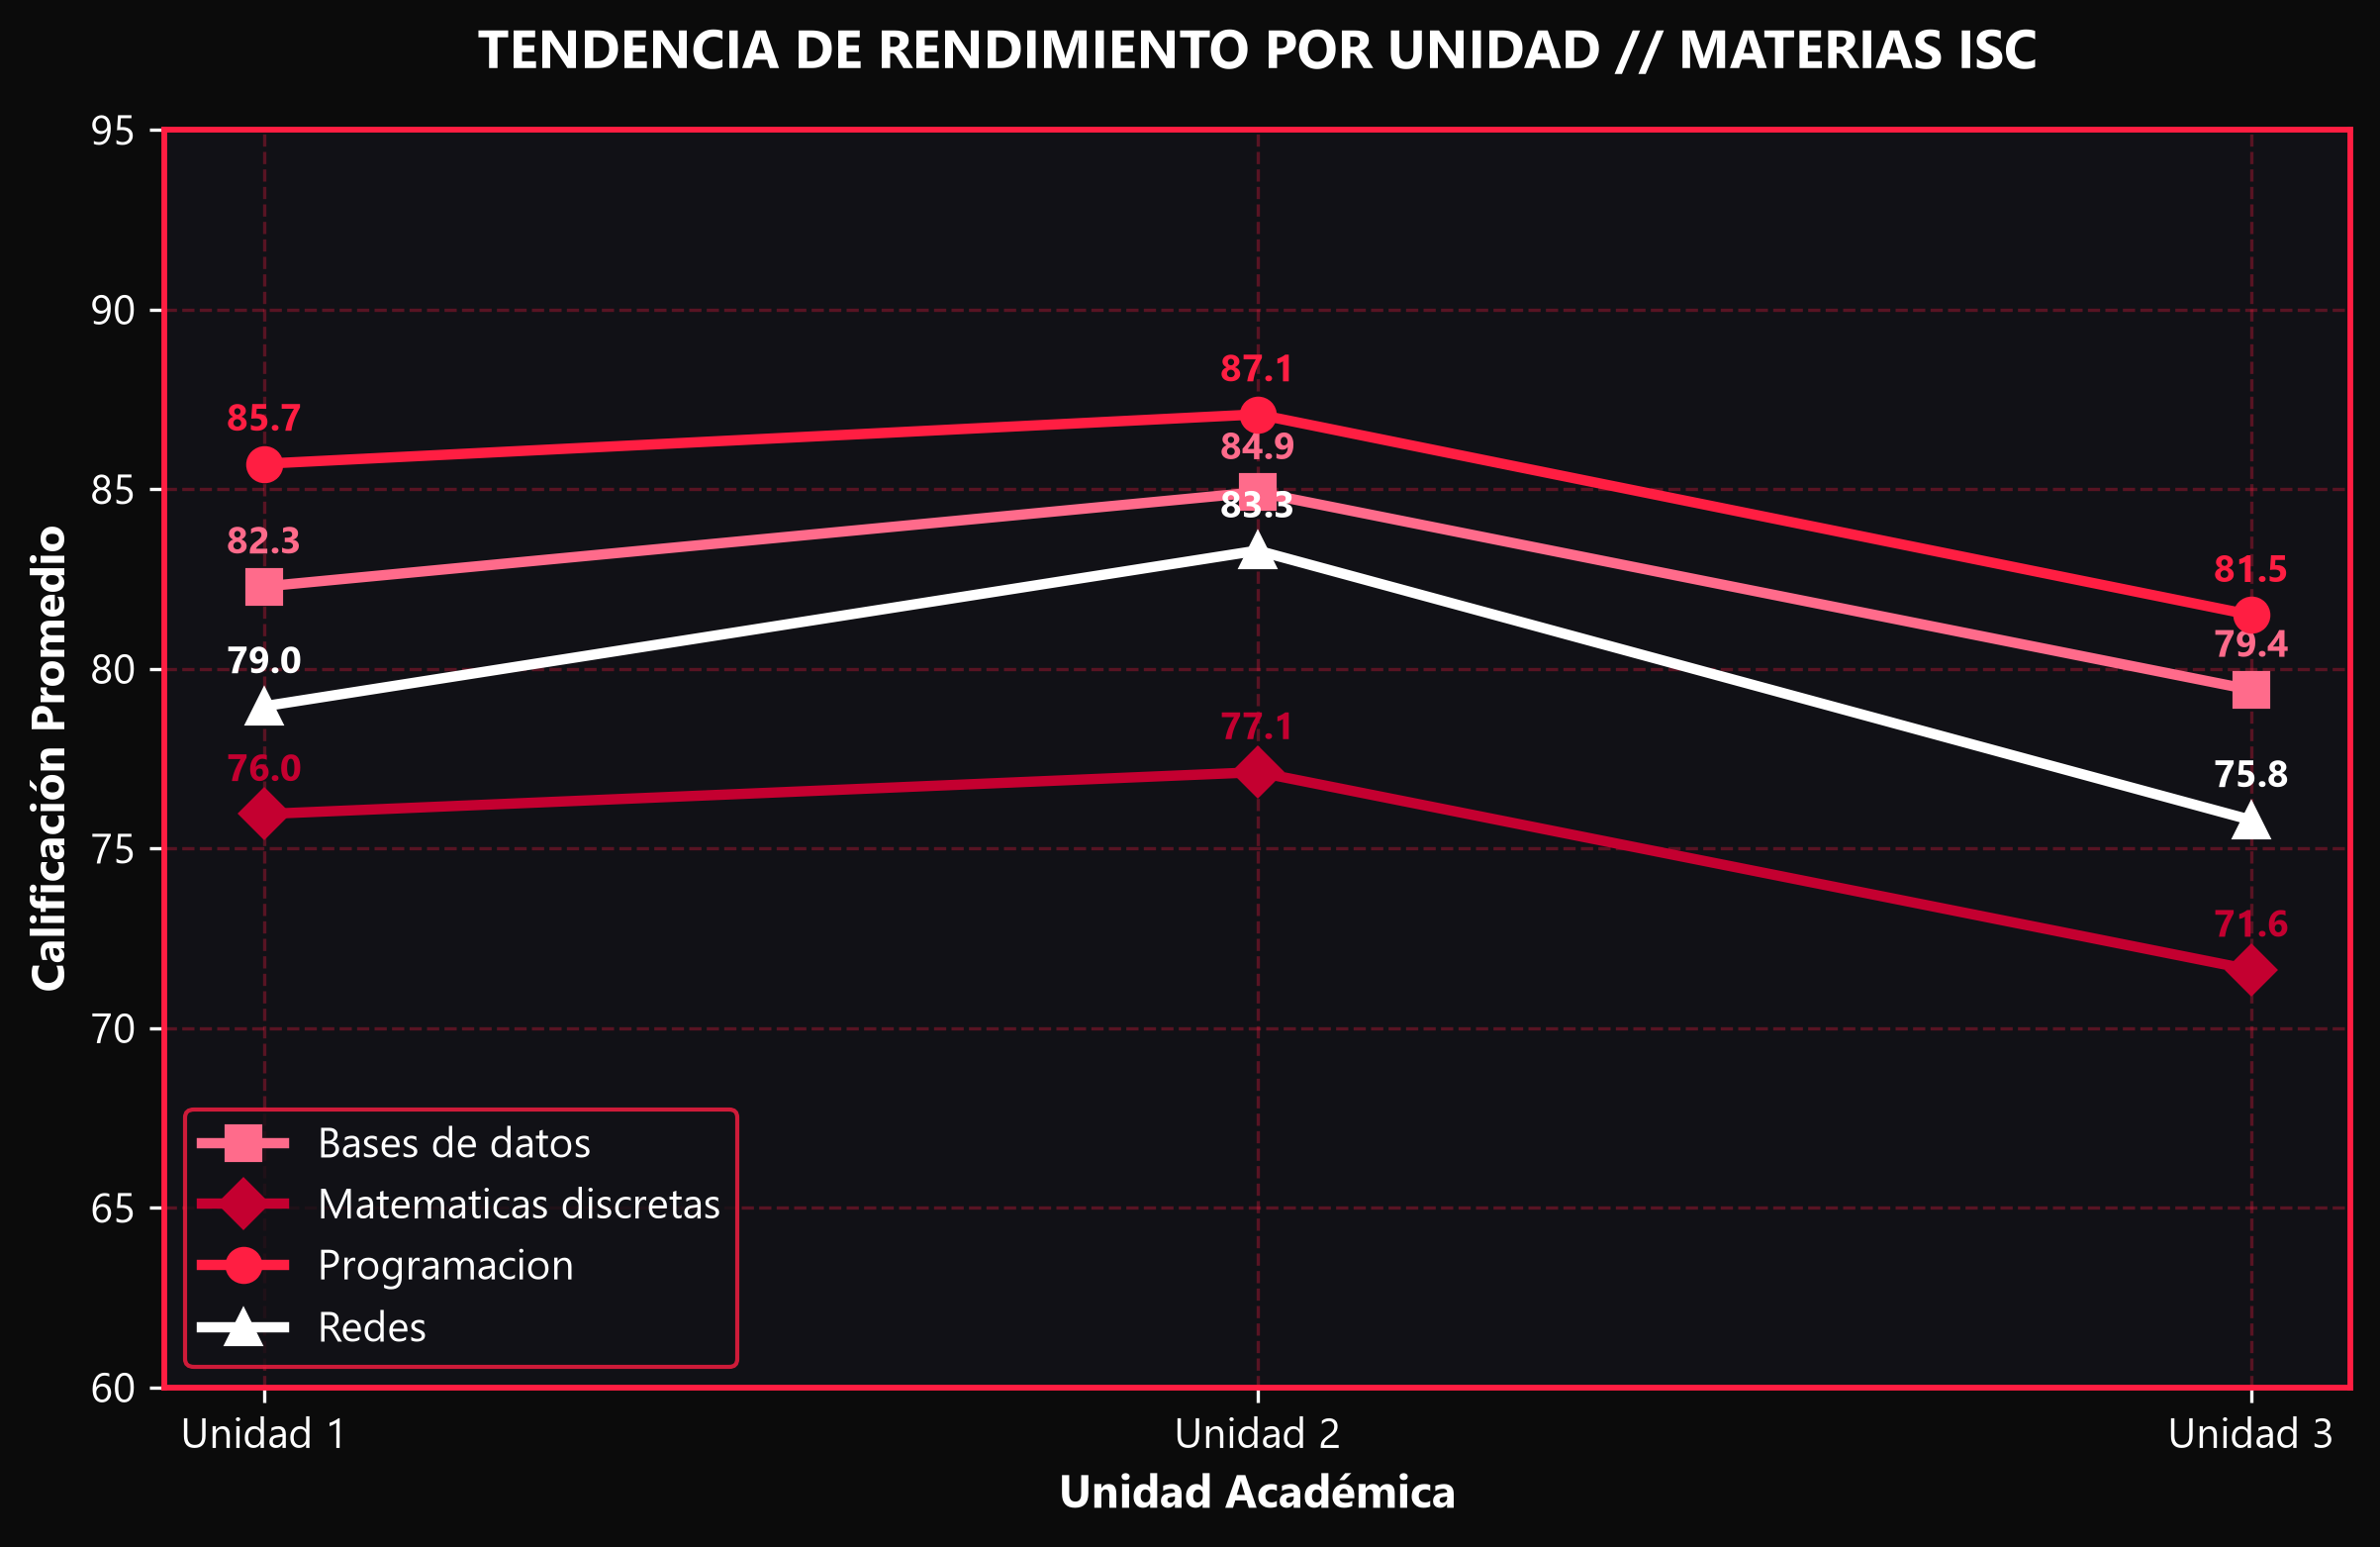

In [8]:
fig3, ax3 = plt.subplots(figsize=(9.5, 5.5), dpi=300)

evolucion_materias = df.groupby(["materia", "unidad"])["calificacion"].mean().unstack(level=0)

colores_materias = {
    "Programacion": "#ff1e42",          # Neón Red
    "Bases de datos": "#ff6b8b",        # Coral Rosado Neón
    "Redes": "#ffffff",                 # Blanco Neón
    "Matematicas discretas": "#c40030"  # Carmesí Profundo
}

marcadores = {
    "Programacion": "o",
    "Bases de datos": "s",
    "Redes": "^",
    "Matematicas discretas": "D"
}

for materia in evolucion_materias.columns:
    color_linea = colores_materias.get(materia, "#ff1e42")
    marcador = marcadores.get(materia, "o")
    ax3.plot(
        evolucion_materias.index,
        evolucion_materias[materia],
        marker=marcador,
        markersize=8,
        linewidth=2.5,
        color=color_linea,
        label=materia,
        zorder=3
    )

    for u in evolucion_materias.index:
        val = evolucion_materias.loc[u, materia]
        ax3.annotate(
            f"{val:.1f}",
            (u, val),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=9,
            color=color_linea,
            fontweight="bold"
        )

ax3.set_xticks([1, 2, 3])
ax3.set_xticklabels(["Unidad 1", "Unidad 2", "Unidad 3"])
ax3.set_ylim(60, 95)
ax3.set_xlabel("Unidad Académica", color="#ffffff", fontweight="bold")
ax3.set_ylabel("Calificación Promedio", color="#ffffff", fontweight="bold")
ax3.set_title("TENDENCIA DE RENDIMIENTO POR UNIDAD // MATERIAS ISC", color="#ffffff", fontweight="bold", pad=15)
ax3.grid(True, linestyle="--", alpha=0.3, color="#ff1e42", zorder=0)
ax3.legend(loc="lower left", facecolor="#111116", edgecolor="#ff1e42", labelcolor="#ffffff")

# Guardar figura a 300 DPI
plt.savefig("tendencia_unidades.png", dpi=300, bbox_inches="tight", facecolor=fig3.get_facecolor())
plt.savefig("static/plots/tendencia_unidades.png", dpi=300, bbox_inches="tight", facecolor=fig3.get_facecolor())
print("✅ Gráfica guardada: tendencia_unidades.png (300 DPI)")
plt.show()

---
## 🧠 Ejercicio 6: Interpretación y Preguntas de Análisis
En esta sección se resuelven formalmente las 3 preguntas clave del análisis con base en las evidencias estadísticas extraídas de los datos:

### 1. ¿Cuál materia tuvo el menor promedio general?
> **Respuesta:** **Matemáticas discretas** con un promedio de **74.90 puntos**.  
> **Justificación Académica:** Esta asignatura demanda un alto nivel de abstracción matemática formal (lógica proposicional, teoría de grafos, relaciones y combinatoria), conceptos teóricos que tradicionalmente presentan mayor dificultad conceptual y menor tasa de aprobación relativa frente a asignaturas con talleres de codificación directa como *Programación* (84.76 pts).

### 2. ¿Qué tendencia se observa en la Unidad 3 respecto a las Unidades 1 y 2?
> **Respuesta:**
> - Unidad 1: **80.73 pts**
> - Unidad 2: **83.10 pts**
> - Unidad 3: **77.08 pts**  
> **Análisis:** Se presenta una **caída sistemática de 6.02 puntos** en la Unidad 3 en relación con la Unidad 2. Esta desaceleración responde a la dinámica habitual de fin de semestre: confluencia simultánea de exámenes finales acumulativos, entrega de proyectos integradores de software y saturación de entregables en todas las asignaturas al mismo tiempo.

### 3. ¿Cuántos alumnos tienen un promedio general menor a 70?
> **Respuesta:** Exactamente **4 alumnos** de los 24 evaluados (**16.7%** del cuerpo estudiantil en condición de riesgo académico):
> 1. `ISC240109` — **Mateo Vargas** (Grupo A): **64.25 pts**
> 2. `ISC240119` — **Santiago Gomez** (Grupo B): **62.17 pts**
> 3. `ISC240105` — **Diego Ramirez** (Grupo A): **57.83 pts**
> 4. `ISC240123` — **Nicolas Paredes** (Grupo B): **57.58 pts**

In [9]:
# Verificación computacional automatizada de las 3 preguntas
print("=" * 70)
print("VERIFICACIÓN AUTOMATIZADA DE RESPUESTAS (EJERCICIO 6)")
print("=" * 70)

# 1. Materia con menor promedio
materia_min = prom_materia.idxmin()
val_min = prom_materia.min()
print(f"1) Materia con menor promedio: '{materia_min}' ({val_min:.2f} pts)")

# 2. Diferencia entre Unidad 2 y Unidad 3
u1, u2, u3 = prom_unidad.loc[1], prom_unidad.loc[2], prom_unidad.loc[3]
print(f"2) Promedios por Unidad: U1={u1:.2f} | U2={u2:.2f} | U3={u3:.2f}")
print(f"   Variación U2 -> U3: {u3 - u2:+.2f} pts (decremento al cierre de semestre)")

# 3. Alumnos con promedio menor a 70
alumnos_riesgo = prom_alumnos[prom_alumnos["promedio_calificacion"] < 70]
print(f"\n3) Total de alumnos con promedio general < 70: {len(alumnos_riesgo)} alumnos ({len(alumnos_riesgo)/24*100:.1f}%)")
for _, r in alumnos_riesgo.iterrows():
    print(f"   • Matrícula {r['matricula']} | {r['nombre']} (Grupo {r['grupo']}): {r['promedio_calificacion']:.2f} pts")

VERIFICACIÓN AUTOMATIZADA DE RESPUESTAS (EJERCICIO 6)
1) Materia con menor promedio: 'Matematicas discretas' (74.90 pts)
2) Promedios por Unidad: U1=80.73 | U2=83.10 | U3=77.08
   Variación U2 -> U3: -6.02 pts (decremento al cierre de semestre)

3) Total de alumnos con promedio general < 70: 4 alumnos (16.7%)
   • Matrícula ISC240109 | Mateo Vargas (Grupo A): 64.25 pts
   • Matrícula ISC240119 | Santiago Gomez (Grupo B): 62.17 pts
   • Matrícula ISC240105 | Diego Ramirez (Grupo A): 57.83 pts
   • Matrícula ISC240123 | Nicolas Paredes (Grupo B): 57.58 pts


---
## 🏆 Conclusiones del Proyecto
1. **Rendimiento de Pandas:** El uso estricto de filtros booleanos y `np.where()` permitió procesar las 288 observaciones de forma instantánea sin bucles iterativos.
2. **Entregables Generados:**
   - Dataset inicial: [`calificaciones_isc.csv`](calificaciones_isc.csv) (288 filas).
   - Resumen exportado: [`promedios_alumnos.csv`](promedios_alumnos.csv) (24 alumnos).
   - Figuras Cyberpunk: [`promedio_materias.png`](promedio_materias.png), [`histograma.png`](histograma.png) y [`tendencia_unidades.png`](tendencia_unidades.png).
3. **Plataforma Web Complementaria:** El servidor local [`app.py`](app.py) expone estas mismas analíticas en un Dashboard interactivo accesible en `http://127.0.0.1:5000/`.